# 09-FreeRTOS中断优先级与中断管理


## 1. 本篇内容与学习目标

本篇是《FreeRTOS 从入门到实战》十七篇笔记中的第09篇，对应 `14中断管理.pptx`，原课标题为**freeRTOS 中断管理**。

课程的主线是：先理解 Cortex-M 的中断优先级数字规则，再确定哪些中断可以调用 FreeRTOS 的 `FromISR` 接口，最后用临界区 API 和按键控制 UART 中断的实战场景把规则落到工程代码中。

| 课件主线 | 本篇学习内容 |
|---|---|
| Cortex-M 优先级模型 | 优先级分组、抢占优先级与“数值越小越紧急” |
| FreeRTOS 管理范围 | `configMAX_SYSCALL_INTERRUPT_PRIORITY` 与 ISR 调用边界 |
| 临界区 API | 普通任务和 ISR 的成对进入、退出接口 |
| 实战与规范 | 按键屏蔽/恢复 UART 接收中断，以及工程检查清单 |

以下按 PPT 第1—9页整理，第10页是品牌结束页。涉及底层实现的补充使用官方 FreeRTOS-Kernel V10.5.1 的 Cortex-M4F 参考端口；该版本未被确认为课程源码版本，也没有据此声称完成开发板编译或运行。


## 2. Cortex-M 中断优先级模型：先看数字含义

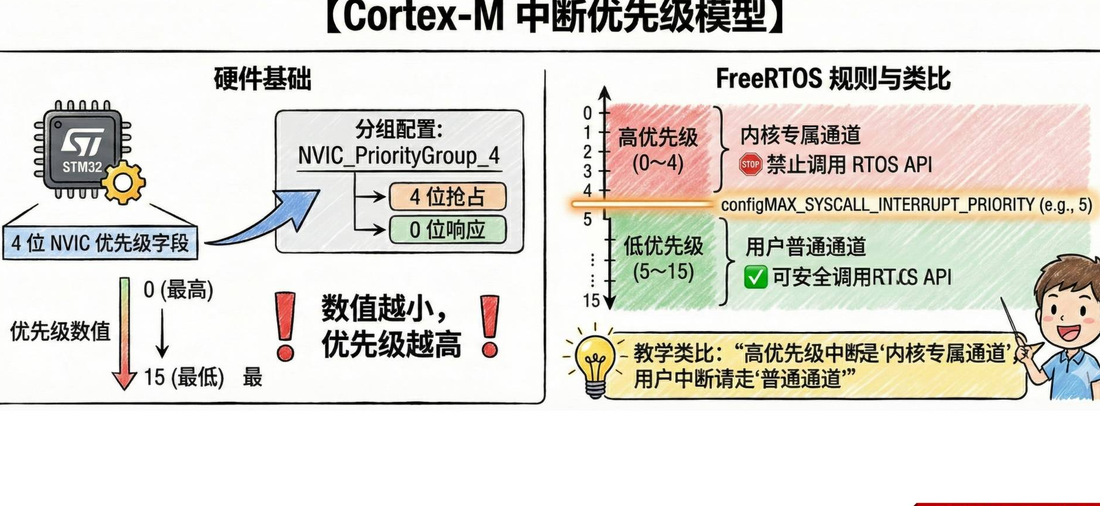

Cortex-M 的中断优先级数字与直觉相反：**数值越小，逻辑优先级越高，响应越紧迫**。在课件示例中，优先级0比优先级5更紧急，优先级15最低。不能把“数字大”理解成“优先级高”。

课件推荐使用 `4:0` 的优先级分组：4位用于抢占优先级，0位用于响应/子优先级。这样比较主要由抢占优先级决定，便于 FreeRTOS 按阈值管理中断。示例配置写作：

```c
NVIC_SetPriorityGrouping(4);  // 课件以 STM32 库的 PriorityGroup_4 表示 4 位抢占、0 位响应
```

这里的数字来自厂商 HAL/CMSIS 的分组枚举命名，不能脱离所用库直接把 `4` 当作所有平台统一的寄存器值。实际工程应确认 `NVIC_SetPriorityGrouping()` 的 API 定义和芯片实现。官方参考端口在检查时要求优先级位都用于抢占优先级；如果厂商库的分组编码与课件不同，应按芯片手册和库文档配置，不能盲目覆盖已有工程设置。

优先级分组决定“哪些位参与抢占比较”，而 `configMAX_SYSCALL_INTERRUPT_PRIORITY` 决定 FreeRTOS 可管理的优先级边界。两者必须在同一套 NVIC 配置下理解。


## 3. FreeRTOS 的中断管理区与非管理区

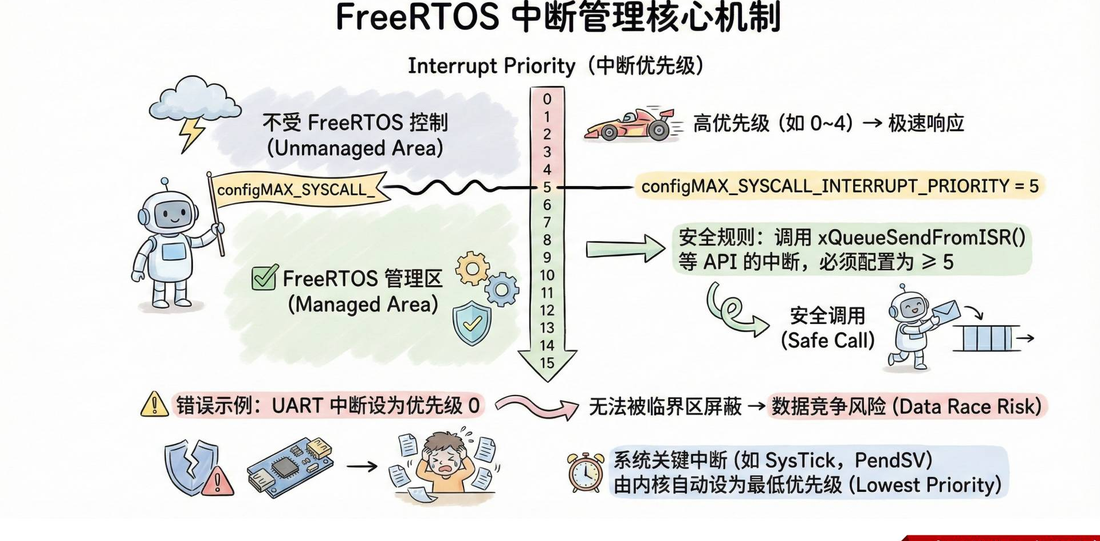

课件以4位优先级字段、`configMAX_SYSCALL_INTERRUPT_PRIORITY = 5` 为例，把中断划分成两个区域：

| 优先级数值 | 区域 | 能否调用 FreeRTOS ISR API |
|---|---|---|
| 0～4 | 高紧迫性、FreeRTOS 不管理区 | 不能调用 `xQueueSendFromISR()` 等内核接口 |
| 5～15 | 用户普通通道、FreeRTOS 管理区 | 满足端口约束时可以调用 `FromISR` 接口 |

这里的“高优先级”仍然指更紧急的优先级，数值反而更小。管理区的下界用数值表示为 `>= configMAX_SYSCALL_INTERRUPT_PRIORITY`；如果某个 ISR 的优先级数值小于5，它可能打断内核临界区，却没有资格调用 FreeRTOS 内核 API。

`configMAX_SYSCALL_INTERRUPT_PRIORITY` 不是把所有中断关掉的开关，而是端口用于 `BASEPRI` 的屏蔽阈值。以 Cortex-M4F 参考端口为例，阈值屏蔽达到该范围的中断，优先级数值更小、紧迫性更高的中断仍可能执行。NMI 等异常也不由这个机制阻止。

SysTick 和 PendSV 是内核相关异常，课件说明它们由内核设置为最低优先级。具体端口仍应查看实际启动代码和配置；不能仅凭一张课件图推断所有 Cortex-M 工程的最终寄存器值。

使用 `FromISR` API 前，应同时核对：中断优先级数字、优先级分组、`configMAX_SYSCALL_INTERRUPT_PRIORITY`，以及当前端口是否启用了优先级合法性检查。


## 4. 为什么不能在应用层直接使用 `portDISABLE_INTERRUPTS()`

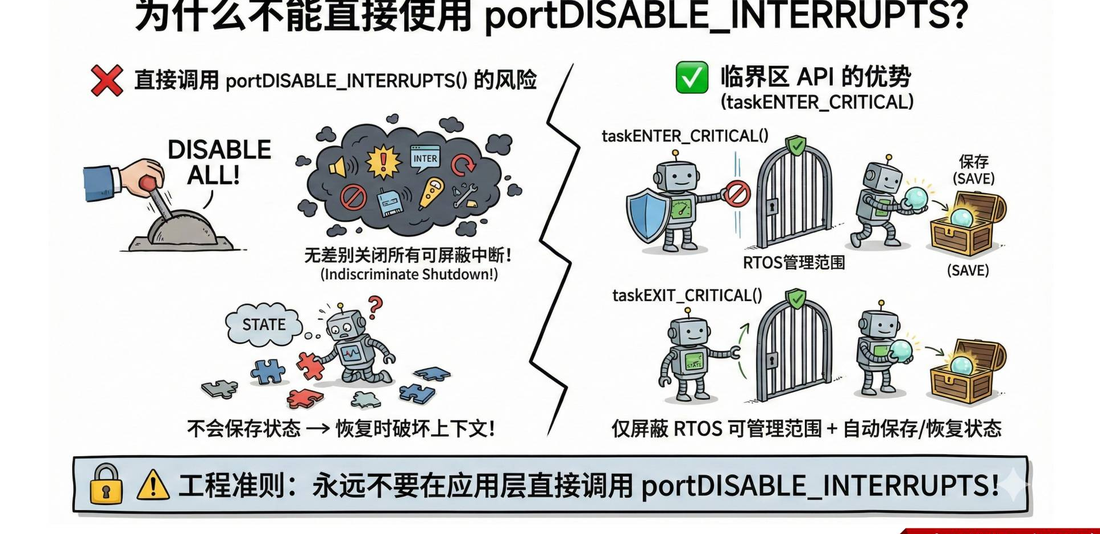

课件把直接调用 `portDISABLE_INTERRUPTS()` 归纳为两个风险：

1. 它可能无差别地关闭应用认为“可屏蔽”的中断，导致串口、定时器等外设响应延迟。
2. 直接操作不能自动保存并恢复进入前的嵌套状态，退出时可能破坏上下文，留下难以定位的时序问题。

应用代码应使用 `taskENTER_CRITICAL()` 与 `taskEXIT_CRITICAL()`。这对 API 由 FreeRTOS 管理屏蔽范围和嵌套计数，调用者只需要保证每次进入都有对应退出。

> 需要限定课件中的“关闭所有中断”说法：在本系列采用的 Cortex-M4F 参考端口中，任务临界区通过设置 `BASEPRI` 屏蔽一部分优先级范围，并非无条件关闭所有中断。不能因此把临界区理解成对所有异常都绝对屏蔽。

官方 V10.5.1 参考端口的相关宏关系如下，代码仅用于说明调用链：

```c
// include/task.h
#define taskENTER_CRITICAL() portENTER_CRITICAL()
#define taskEXIT_CRITICAL()  portEXIT_CRITICAL()

// portable/RVDS/ARM_CM4F/portmacro.h
#define portENTER_CRITICAL()              vPortEnterCritical()
#define portEXIT_CRITICAL()               vPortExitCritical()
#define portDISABLE_INTERRUPTS()          vPortRaiseBASEPRI()
#define portENABLE_INTERRUPTS()           vPortSetBASEPRI(0)
#define portSET_INTERRUPT_MASK_FROM_ISR() ulPortRaiseBASEPRI()
#define portCLEAR_INTERRUPT_MASK_FROM_ISR(x) vPortSetBASEPRI(x)
```

该参考端口中，`vPortRaiseBASEPRI()` 使用 `configMAX_SYSCALL_INTERRUPT_PRIORITY` 设置阈值，`vPortEnterCritical()` 还维护临界区嵌套计数。参考源码是实现边界说明，不代表课程工程一定采用 RVDS 目录下的同一份端口。


## 5. 临界区 API：任务与 ISR 必须使用不同版本

普通任务访问需要短暂保护的共享资源时，使用成对的任务接口：

```c
taskENTER_CRITICAL();

// 完成必要且短小的共享数据读、改、写

taskEXIT_CRITICAL();
```

临界区应从共享操作的第一步开始，覆盖完整的读、改、写过程；只保护最后一条写指令不能消除旧值覆盖。所有可能访问同一资源的任务都要遵守同一保护约定。

ISR 中不能直接套用普通任务宏。需要在满足中断优先级约束的前提下，保存进入前的屏蔽状态，并在退出时恢复：

```c
UBaseType_t savedMask;

savedMask = taskENTER_CRITICAL_FROM_ISR();
// ISR 中只完成必要且很短的共享数据访问
taskEXIT_CRITICAL_FROM_ISR(savedMask);
```

`taskENTER_CRITICAL_FROM_ISR()` 返回的值必须传给对应的 `taskEXIT_CRITICAL_FROM_ISR(savedMask)`。这组接口用于保存/恢复 ISR 进入前的状态，不能写成不带参数的普通任务退出宏。

临界区内不应调用 `vTaskDelay()`、等待队列/信号量的阻塞接口，也不应放入 `printf()`、`malloc()` 或大段循环。临界区越长，被屏蔽的中断等待越久，系统响应时间就越差。


## 6. 实战：按键控制 UART 接收中断

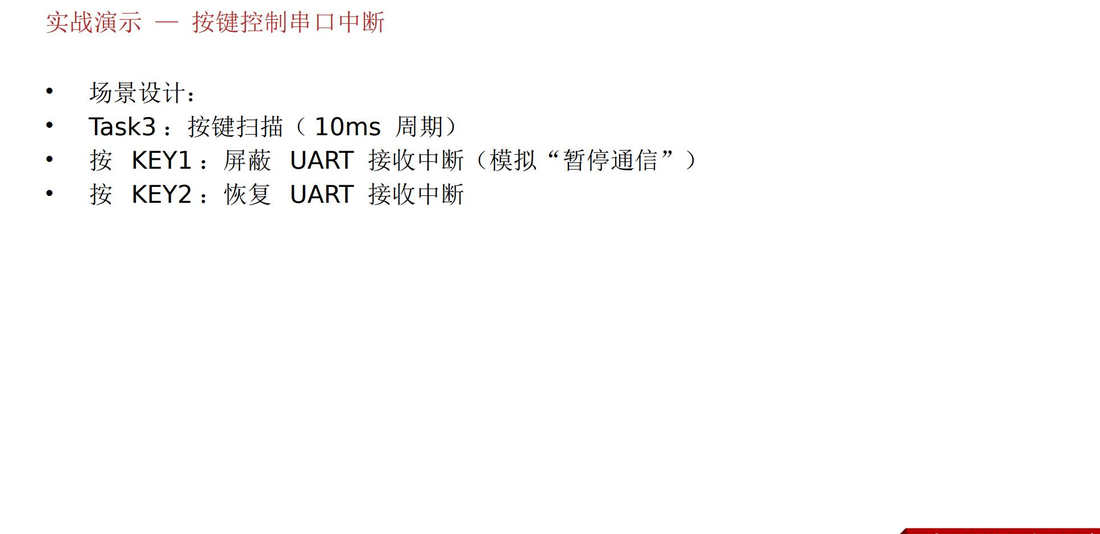

第7页给出的场景是让 `Task3` 以10ms周期扫描按键：

| 操作 | 课件行为 | 目的 |
|---|---|---|
| 按下 `KEY1` | 屏蔽 UART 接收中断 | 模拟“暂停通信” |
| 按下 `KEY2` | 恢复 UART 接收中断 | 恢复串口接收 |

这个例子强调的是**应用层控制中断状态的入口**，不是让任务直接操作底层全局中断寄存器。按键扫描任务可以先读取按键状态，再在很短的临界区内修改受保护的控制变量或调用工程封装的 UART 中断控制函数。

示意代码只表达调用位置，具体 UART 实例、按键宏和 HAL 函数名必须以课程工程为准：

```c
void Task3(void *argument)
{
    for (;;)
    {
        if (KEY1_PRESSED())
        {
            taskENTER_CRITICAL();
            uart_rx_paused = true;
            taskEXIT_CRITICAL();
            // UART 的具体中断屏蔽由工程驱动层根据该状态处理
        }

        if (KEY2_PRESSED())
        {
            taskENTER_CRITICAL();
            uart_rx_paused = false;
            taskEXIT_CRITICAL();
        }

        vTaskDelay(pdMS_TO_TICKS(10));
    }
}
```

课件没有展示完整的 `Task3`、UART 初始化或按键消抖实现，因此这里不伪造具体寄存器和 HAL 调用。真实项目还要处理按键消抖、重复触发以及 UART 接收缓冲区在暂停期间的溢出策略。


## 7. 工程最佳实践：把规则变成检查项

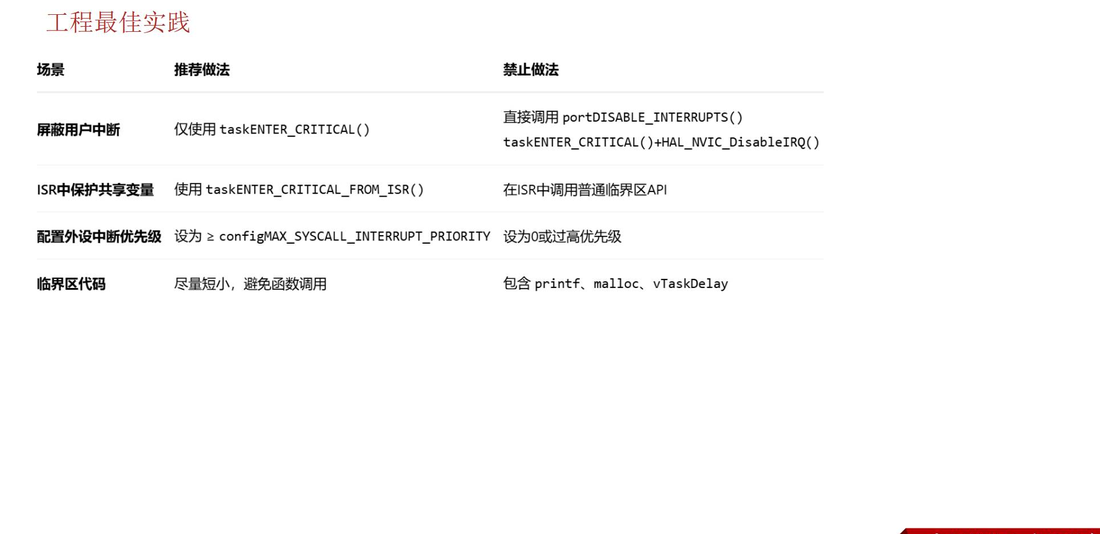

第8页的工程表格可以整理成以下检查项：

| 场景 | 推荐做法 | 禁止或风险做法 |
|---|---|---|
| 屏蔽用户中断 | 使用 `taskENTER_CRITICAL()` | 直接调用 `portDISABLE_INTERRUPTS()` |
| ISR 保护共享变量 | 使用 `taskENTER_CRITICAL_FROM_ISR()` | 在 ISR 中调用普通任务临界区 API |
| 外设中断优先级 | 设置为 `>= configMAX_SYSCALL_INTERRUPT_PRIORITY` | 设置为0或其他更高紧迫性后调用 FreeRTOS API |
| 临界区代码 | 尽量短，避免函数调用 | 放入 `printf`、`malloc`、`vTaskDelay` |

注意“设置为 `>=`”比较的是**优先级数值**。例如阈值为5时，优先级5、6、7可以进入管理区；优先级0～4虽然更紧急，却不能调用 `FromISR` API。

如果高紧迫性 ISR 必须运行，它可以不使用 FreeRTOS API，但它仍可能打断任务临界区。若它与任务共同修改同一数据，应设计更合适的无锁协议、硬件原子操作或数据交换方式，不能假定任务临界区会自动保护它。


## 8. 中断优先级与 `FromISR` API 的源码边界

官方 FreeRTOS-Kernel V10.5.1 参考端口的 `vPortValidateInterruptPriority()` 会检查当前 ISR 的优先级数值是否满足 `>= configMAX_SYSCALL_INTERRUPT_PRIORITY`。这说明“能调用 `FromISR`”不是 API 名字本身决定的，而是由端口、NVIC 优先级和配置共同决定。

参考端口相关规则可概括为：

```text
ISR 优先级数值 < configMAX_SYSCALL_INTERRUPT_PRIORITY
    -> 更紧急，不能调用 FreeRTOS ISR API

ISR 优先级数值 >= configMAX_SYSCALL_INTERRUPT_PRIORITY
    -> 在分组和端口配置正确时，才可调用 FromISR API
```

因此，调用 `xQueueSendFromISR()`、`xSemaphoreGiveFromISR()` 等接口后，还要按接口要求检查 `pxHigherPriorityTaskWoken`，必要时请求一次任务切换。这里的“允许调用”不等于“可以在 ISR 中执行任意任务代码”：ISR 仍要短小，不能调用会阻塞的普通任务接口。

优先级分组也必须一致。若工程把部分优先级位用于响应/子优先级，而端口检查按全抢占优先级解释，可能出现配置与实际行为不一致。修改分组前应检查 HAL/CMSIS 初始化、启动代码和现有中断配置，不能只改 `FreeRTOSConfig.h`。


## 9. 临界区的设计边界与常见误区

### 误区一：把临界区当成“永远关闭所有中断”

在 Cortex-M4F 参考端口中，任务临界区主要通过 `BASEPRI` 形成阈值屏蔽。数值更小的高紧迫性中断仍可能运行，NMI 等异常也不受其控制。工程文档应写清楚端口行为，不要用绝对化表述代替硬件规则。

### 误区二：只保护写回，不保护读取

共享计数、状态位或环形缓冲区索引的读、改、写必须作为整体保护。只把 `shared = value` 放进临界区，读取的旧值仍可能在临界区外已经失效。

### 误区三：在临界区里等待

临界区里调用 `vTaskDelay()`、队列接收或信号量获取，会让中断延迟和调度约束互相冲突。先退出临界区，再执行等待；若资源保护需要跨越等待，应使用互斥量或其他同步机制。

### 误区四：把 `FromISR` 当成“任何中断都能用”

只有处于 FreeRTOS 管理区的 ISR 才能安全调用这些接口。优先级0～4的 ISR 必须保持独立，不能为了发送队列消息而强行调用内核 API。

### 误区五：用按键直接操作底层中断寄存器

按键实战应通过 RTOS 临界区和驱动层封装控制 UART 接收状态，避免应用代码直接混用 `portDISABLE_INTERRUPTS()`、`HAL_NVIC_DisableIRQ()` 和临界区宏，导致状态无法成对恢复。


## 10. 本课要点与验证步骤

课件第9页总结了五条规则：FreeRTOS 只管理优先级数值 `>= configMAX_SYSCALL_INTERRUPT_PRIORITY` 的中断；优先级分组推荐4:0全抢占模式；临界区优于直接操作中断；按键或任务中屏蔽中断要配合临界区；ISR 必须使用 `FROM_ISR` 版本的临界区 API。

结合官方 V10.5.1 参考端口，可以按下面顺序核对课程工程：

1. 查启动代码和 HAL/CMSIS 配置，确认 NVIC 优先级分组以及每个外设中断的优先级数值。
2. 查 `FreeRTOSConfig.h`，确认 `configMAX_SYSCALL_INTERRUPT_PRIORITY` 的值与优先级字段宽度相匹配。
3. 搜索所有 `FromISR` API 调用，逐一确认所在 ISR 的优先级数值不小于阈值。
4. 搜索 `portDISABLE_INTERRUPTS()`、`HAL_NVIC_DisableIRQ()` 等直接操作，改为工程规定的临界区或驱动封装，并检查进入/退出是否成对。
5. 检查临界区内部没有 `printf`、`malloc`、`vTaskDelay` 或等待接口，且只覆盖必要的共享数据访问。
6. 对按键 UART 实战，确认 `Task3` 的10ms扫描、KEY1暂停和KEY2恢复逻辑，并补充按键消抖、接收缓存和恢复后的数据处理策略。

以下内容依据课件和参考源码整理，未进行开发板编译、下载或运行，也未伪造 UART 输出或中断时序结果。参考源码边界为官方 FreeRTOS-Kernel V10.5.1，未确认是课程源码版本。
